# Mechanical Wing Structural Analysis
This notebook computes section properties, validates coordinate-frame transforms, and compares direct structural-property calculations against scaling-law estimates along the half-span.

In [27]:
from sectionproperties.analysis import Section
from sectionproperties.pre import CompoundGeometry, Geometry
from aerosandbox.geometry.airfoil.airfoil_families import get_kulfan_parameters, get_kulfan_coordinates
import pandas as pd
from shapely.geometry import Polygon, LineString, Point
from shapely.ops import unary_union
import aerosandbox.numpy as np
from sectionproperties.pre import Material
import matplotlib.pyplot as plt 
from tqdm import tqdm

from generative_inverse_wing_design.DataGenerator.utils import (
    area_preserving_boxcar,
    compose_scaled_properties,
    create_i_beam_polygon,
    create_rib_polygon,
    get_airfoil_properties,
    interpolate_smoothed,
    make_open_thin_walled_section,
    offset_airfoil_inward,
    rotate_ei_about_shear_center,
    rotate_polygon_about_point,
)

## 1) Sanity Check with a Tube Section
Quick validation that `sectionproperties` outputs expected values with and without assigned material properties.

In [28]:
# Create a simple tube geometry for testing
outer_radius = 0.05  # 5 cm
inner_radius = 0.04  # 4 cm
outer_circle = Point(0, 0).buffer(outer_radius, resolution=32)
inner_circle = Point(0, 0).buffer(inner_radius, resolution=32)
tube_polygon = outer_circle.difference(inner_circle)

# Define aluminum material
aluminum = Material(
    name="Aluminum",
    elastic_modulus=71.7e9,  # Pa
    poissons_ratio=0.33,
    density=2810,  # kg/m3
    yield_strength=430e6,  # Pa
    color="lightgrey"
)


In [29]:
# Create geometry with material and analyze
geometry_with_material = Geometry(geom=tube_polygon, material=aluminum)
geometry_with_material.create_mesh(mesh_sizes=[0.002])
section_with_material = Section(geometry=geometry_with_material)
section_with_material.calculate_geometric_properties()
section_with_material.calculate_warping_properties()

j_w_material = section_with_material.get_ej()  # Torsional constant with material
i_w_material = section_with_material.get_eic()  # Bending stiffness with material$

print(f"Torsional constant with material: {j_w_material} Nm^2")
print(f"Bending stiffness with material: EIxx = {i_w_material[0]}, EIyy = {i_w_material[1]}, EIxy = {i_w_material[2]} Nm^2")

Torsional constant with material: 415256.6190278863 Nm^2
Bending stiffness with material: EIxx = 207628.3095139431, EIyy = 207628.30951394318, EIxy = -1.979572061827639e-11 Nm^2


In [30]:
# Create geometry with material and analyze
geometry = Geometry(geom=tube_polygon)
geometry.create_mesh(mesh_sizes=[0.002])
section = Section(geometry=geometry)
section.calculate_geometric_properties()
section.calculate_warping_properties()

j_w_material = section.get_j()  # Torsional constant with material
i_w_material = section.get_ic()  # Bending stiffness with material
area = section.get_area()

print(f"Cross-sectional area: {area} m^2")
print(f"Torsional constant without material: {j_w_material} Nm^2")
print(f"Bending stiffness without material: EIxx = {i_w_material[0]}, EIyy = {i_w_material[1]}, EIxy = {i_w_material[2]} Nm^2")

Cross-sectional area: 0.0028262980412592236 m^2
Torsional constant without material: 5.791584644740398e-06 Nm^2
Bending stiffness without material: EIxx = 2.895792322370198e-06, EIyy = 2.8957923223701997e-06, EIxy = -4.727337200740552e-22 Nm^2


In [31]:
print(f"Torsional constant without material * E: {j_w_material * aluminum.elastic_modulus} Nm^2")
print(f"Bending stiffness without material * E: EIxx = {i_w_material[0] * aluminum.elastic_modulus}, EIyy = {i_w_material[1] * aluminum.elastic_modulus}, EIxy = {i_w_material[2] * aluminum.elastic_modulus} Nm^2")

Torsional constant without material * E: 415256.61902788654 Nm^2
Bending stiffness without material * E: EIxx = 207628.3095139432, EIyy = 207628.30951394333, EIxy = -3.389500772930976e-11 Nm^2


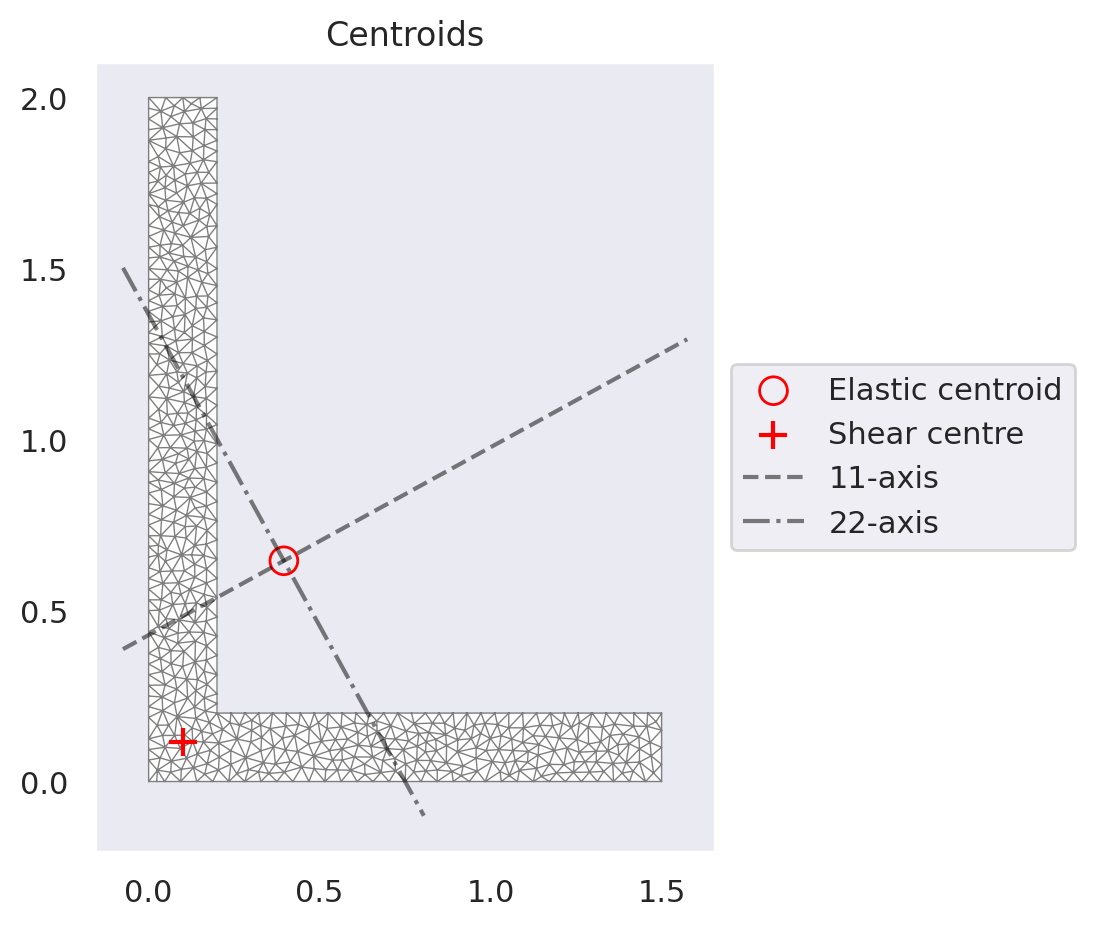

Centroid: [[0.39545455 0.64545455]]
Shear Center: [[0.10082466 0.11638903]]
Original EI: [ 1.87736673e+10  9.07624227e+09 -7.62627273e+09]
Rotated EI: [[ 9.74476510e+09  1.81051444e+10 -8.01224456e+09]]
Directly computed rotated EI: [ 9.74476510e+09  1.81051444e+10 -8.01224456e+09]


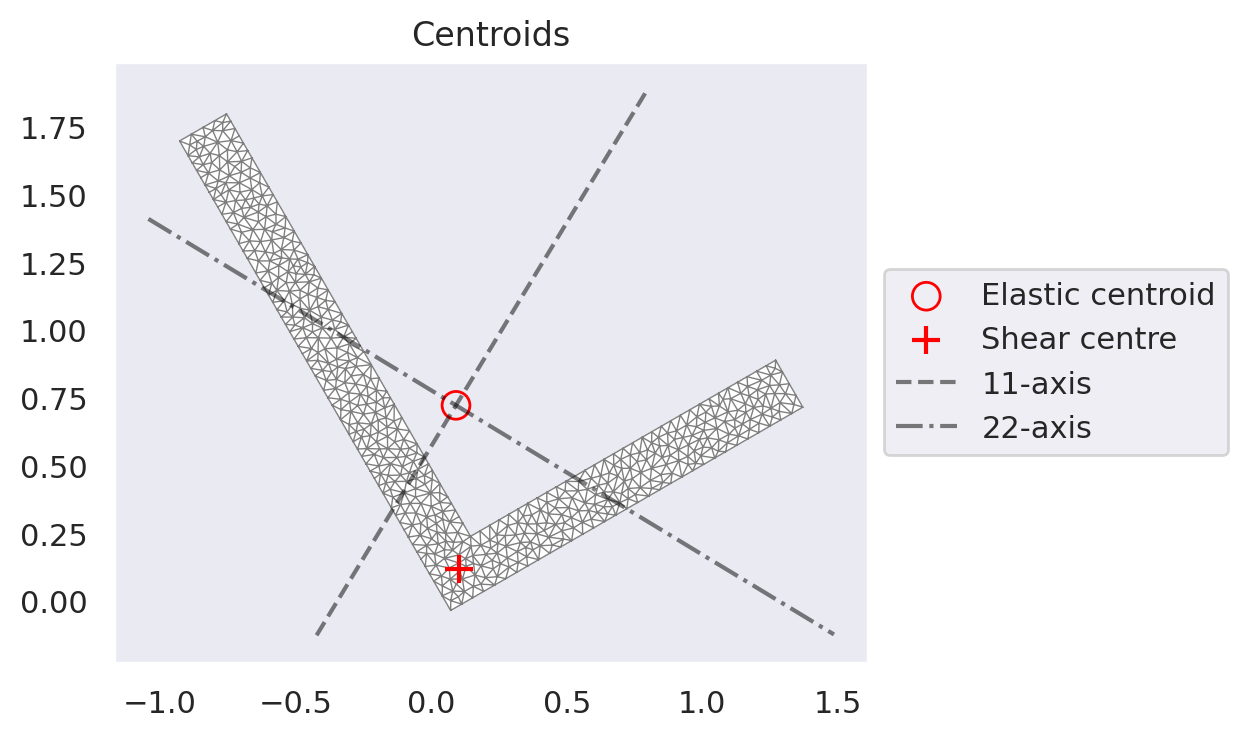

In [32]:
def test_ei_rotation_equivalence():
    # Define material
    aluminum = Material(
        name="Aluminum",
        elastic_modulus=71.7e9,
        poissons_ratio=0.33,
        density=2810,
        yield_strength=430e6,
        color="lightgrey"
    )

    open_section_poly = make_open_thin_walled_section()
    geometry = Geometry(geom=open_section_poly)
    geometry.create_mesh(mesh_sizes=[0.001])
    section = Section(geometry=geometry)
    section.calculate_geometric_properties()
    section.calculate_warping_properties()
    section.plot_centroids()

    area = np.array([section.get_area()])
    I = section.get_ic()  # Bending stiffness without material
    EI_original = np.array([
        I[0] * aluminum.elastic_modulus,
        I[1] * aluminum.elastic_modulus,
        I[2] * aluminum.elastic_modulus,
    ])
    centroid = np.array([section.get_c()])
    shear_center = np.array([section.get_sc()])
    print("Centroid:", centroid)
    print("Shear Center:", shear_center)
    twist_angle = np.array([np.radians(30)])  # Rotate by 30 degrees

    EI_rotated = rotate_ei_about_shear_center(
        EI_original.reshape(1, 3),
        twist_angle,
        centroid,
        shear_center,
        area,
        aluminum.elastic_modulus,
    )
    print("Original EI:", EI_original)
    print("Rotated EI:", EI_rotated)

    rotated_polygon = rotate_polygon_about_point(
        open_section_poly,
        twist_angle[0],
        shear_center[0],
    )
    geometry_rotated = Geometry(geom=rotated_polygon)
    geometry_rotated.create_mesh(mesh_sizes=[0.001])
    section_rotated = Section(geometry=geometry_rotated)
    section_rotated.calculate_geometric_properties()
    section_rotated.calculate_warping_properties()
    I_rotated_directly = section_rotated.get_ic()
    EI_rotated_directly = np.array([
        I_rotated_directly[0],
        I_rotated_directly[1],
        I_rotated_directly[2],
    ]) * aluminum.elastic_modulus

    print("Directly computed rotated EI:", EI_rotated_directly)
    section_rotated.plot_centroids()


test_ei_rotation_equivalence()

## 2) EI Rotation Validation About Shear Center
The transform is validated on a simple open section: shift to shear center, rotate, and shift back.

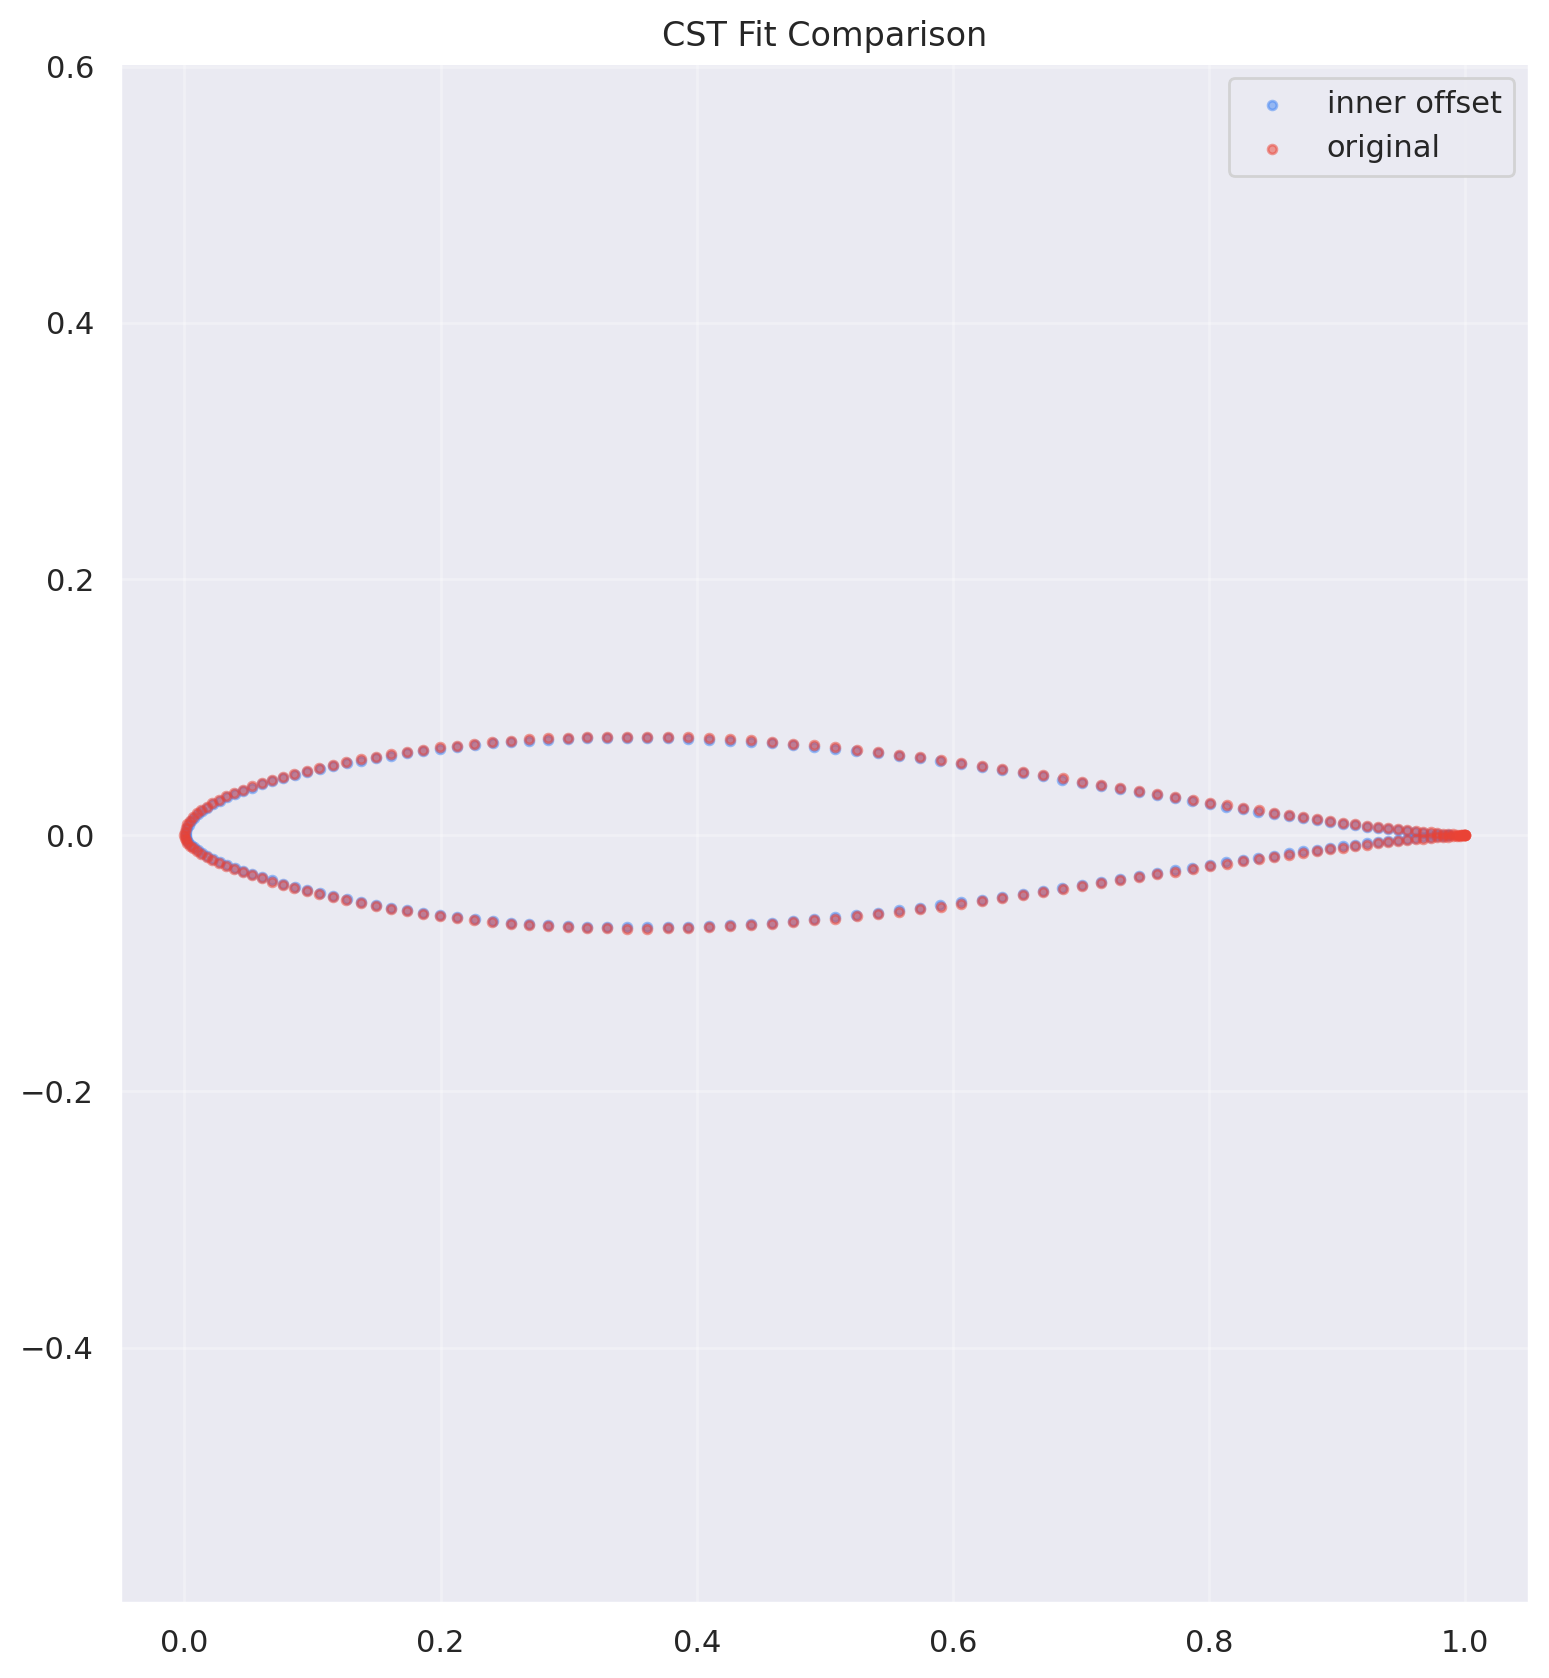

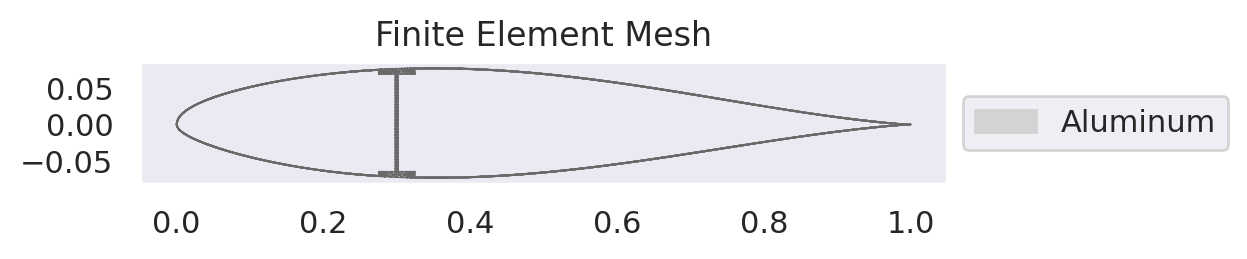

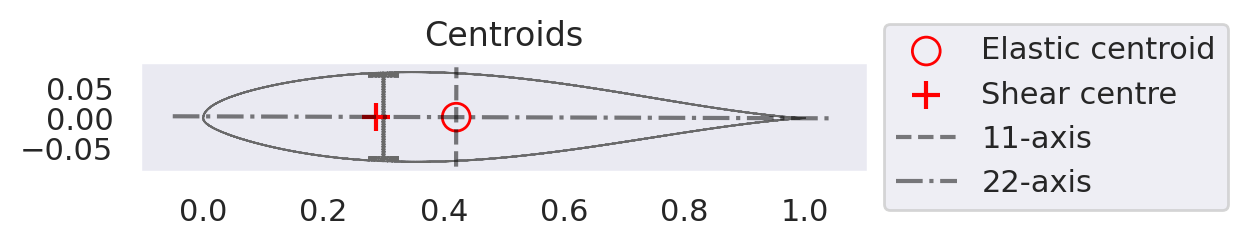

Shear Center: x=0.288339, y=0.002478
Cross-sectional area: 0.003206
Centroid: x=0.420771, y=0.001744
Bending Stiffness E*Ixx: 6.774627e+05
Bending Stiffness E*Iyy: 1.418834e+07
Torsion Stiffness G*J: 1.292371e+06


In [51]:
from pathlib import Path

dim_per_side = 3
n_points_per_side = 96
wall_thickness = 0.001  # 1 mm wall thickness
beam_thickness = 0.005  # 5 mm beam thickness
beam_cap_lengths = 0.05  # 5 cm cap lengths
chord_length = 1  # Normalized chord length
beam_position = 0.3  # Position along chord (0 to 1)
airfoil_idx = 555

# Path-agnostic lookup: search current folder and all parents for data/processed/airfoil_with_polars.csv
csv_rel_path = Path("data") / "processed" / "airfoil_with_polars.csv"
airfoil_csv_path = next(
    (base / csv_rel_path for base in [Path.cwd(), *Path.cwd().parents] if (base / csv_rel_path).exists()),
    None,
)

if airfoil_csv_path is None:
    searched = "\n".join(str(base / csv_rel_path) for base in [Path.cwd(), *Path.cwd().parents])
    raise FileNotFoundError(
        f"Could not find '{csv_rel_path}'. Searched:\n{searched}"
    )

airfoil_df = pd.read_csv(airfoil_csv_path)

# Extract CST parameters using correct indexing
uw = []
lw = []

# Get upper weights
for j in range(dim_per_side):
    upper_col = f'asb_upper_{j}'
    uw.append(airfoil_df.iloc[airfoil_idx][upper_col])

# Get lower weights
for j in range(dim_per_side):
    lower_col = f'asb_lower_{j}'
    lw.append(airfoil_df.iloc[airfoil_idx][lower_col])

# Get leading edge weight
le = airfoil_df.iloc[airfoil_idx]['asb_leading_edge_weight']

# Create airfoil coordinates
original_coords = get_kulfan_coordinates(
    lower_weights=lw,
    upper_weights=uw,
    leading_edge_weight=le,
    n_points_per_side=n_points_per_side,
    TE_thickness=0
)

coords = original_coords * chord_length  # Scale to chord length
# Create inner offset coordinates
inner_coords = offset_airfoil_inward(coords, wall_thickness)

plt.figure(figsize=(20, 10))
plt.subplot(1, 2, 1)
plt.scatter(inner_coords[:, 0], inner_coords[:, 1], alpha=0.5, label='inner offset', s=10)
plt.scatter(coords[:, 0], coords[:, 1], alpha=0.5, label='original', s=10)
plt.axis('equal')
plt.legend()
plt.title('CST Fit Comparison')
plt.grid(True, alpha=0.3)
plt.show()

# Separate the outer and inner coordinates
outer_points = coords.tolist()
inner_points = inner_coords.tolist()

# Define material (e.g., aluminum)
aluminum = Material(
    name="Aluminum",
    elastic_modulus=71.7e9,
    poissons_ratio=0.33,
    density=2810,
    yield_strength=430e6,
    color="lightgrey"
)

# Create outer and inner polygons
outer_poly = Polygon(outer_points)
inner_poly = Polygon(inner_points)

# Create wall region by subtracting inner from outer
wall_region = outer_poly.difference(inner_poly)

i_beam_polygon = create_i_beam_polygon(
    inner_poly,
    chord_length=chord_length,
    beam_position=beam_position,
    beam_thickness=beam_thickness,
    beam_cap_lengths=beam_cap_lengths,
)

airfoil_polygon = wall_region.union(i_beam_polygon)

# Create geometry
airfoil_geom = Geometry(geom=airfoil_polygon, material=aluminum)

# Create mesh
airfoil_geom.create_mesh(mesh_sizes=[0.001])

# Create section and calculate properties
airfoil_sec = Section(geometry=airfoil_geom)

# Calculate properties
airfoil_sec.calculate_geometric_properties()
airfoil_sec.calculate_warping_properties()

# Get results
shear_center = airfoil_sec.get_sc()
area = airfoil_sec.get_area()
centroid = airfoil_sec.get_c()
second_moments = airfoil_sec.get_eic()
torsion_constant = airfoil_sec.get_ej()

airfoil_sec.plot_mesh()
airfoil_sec.plot_centroids()

print(f"Shear Center: x={shear_center[0]:.6f}, y={shear_center[1]:.6f}")
print(f"Cross-sectional area: {area:.6f}")
print(f"Centroid: x={centroid[0]:.6f}, y={centroid[1]:.6f}")
print(f"Bending Stiffness E*Ixx: {second_moments[0]:.6e}")
print(f"Bending Stiffness E*Iyy: {second_moments[1]:.6e}")
print(f"Torsion Stiffness G*J: {torsion_constant:.6e}")

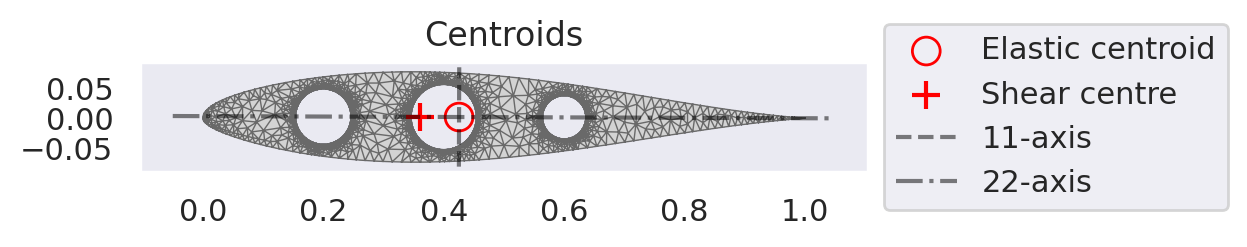

Shear Center: x=0.361012, y=0.002172
Cross-sectional area: 0.074554
Centroid: x=0.425479, y=0.001967
Bending Stiffness E*Ixx: 7.691781e+06
Bending Stiffness E*Iyy: 2.884761e+08
Torsion Stiffness G*J: 2.782957e+07


In [ ]:
rib_polygon = create_rib_polygon(outer_polygon=outer_poly, chord_length=chord_length,
                                         beam_position=beam_position, beam_thickness=beam_thickness,
                                         hole_positions=[0.2, 0.4, 0.6], min_border=0.02)

rib_geometry = Geometry(geom=rib_polygon, material=aluminum)

# Create mesh
rib_geometry.create_mesh(mesh_sizes=[0.001])

# Create section and calculate properties
airfoil_sec = Section(geometry=rib_geometry)

# Calculate properties
airfoil_sec.calculate_geometric_properties()
airfoil_sec.calculate_warping_properties()

# Get results
shear_center = airfoil_sec.get_sc()
area = airfoil_sec.get_area()
centroid = airfoil_sec.get_c()
second_moments = airfoil_sec.get_eic()
torsion_constant = airfoil_sec.get_ej()

airfoil_sec.plot_centroids()

print(f"Shear Center: x={shear_center[0]:.6f}, y={shear_center[1]:.6f}")
print(f"Cross-sectional area: {area:.6f}")
print(f"Centroid: x={centroid[0]:.6f}, y={centroid[1]:.6f}")
print(f"Bending Stiffness E*Ixx: {second_moments[0]:.6e}")
print(f"Bending Stiffness E*Iyy: {second_moments[1]:.6e}")
print(f"Torsion Stiffness G*J: {torsion_constant:.6e}")


## 4) Spanwise Property Sweep
Compute rib and spar section properties along the half-span and assemble piecewise distributions.

In [38]:
span = 15
ys_over_half_span = np.sin(np.linspace(0, np.pi / 2, 5))
rib_positions = 1 - np.cos(np.linspace(0, np.pi / 2, 10))
chords = 1 * (1 - 0.95 * rib_positions) ** 0.5

y = []
shear_centers = []
areas = []
centroids = []
second_moments_list = []
torsion_constants = []

normalized_halfe_beam_thickness = beam_thickness / span

for i, pos in tqdm(enumerate(rib_positions), total=len(rib_positions), desc="Analyzing sections"):
    try:
        scaled_coords = original_coords * chords[i]
        outer_poly = Polygon(scaled_coords.tolist())

        airfoil_polygon_rib = create_rib_polygon(
            outer_polygon=outer_poly,
            chord_length=chords[i],
            beam_position=beam_position,
            beam_thickness=beam_thickness,
            hole_positions=[0.2, 0.4, 0.6],
            min_border=0.02,
        )

        shear_center_rib, area_rib, centroid_rib, second_moments_rib, torsion_constant_rib = get_airfoil_properties(
            airfoil_polygon_rib,
            aluminum,
        )

        inner_coords = offset_airfoil_inward(scaled_coords, wall_thickness)
        inner_poly = Polygon(inner_coords.tolist())

        wall_region = outer_poly.difference(inner_poly)
        i_beam_polygon = create_i_beam_polygon(
            inner_poly,
            chord_length=chords[i],
            beam_position=beam_position,
            beam_thickness=beam_thickness,
            beam_cap_lengths=beam_cap_lengths,
        )
        airfoil_polygon_beam = wall_region.union(i_beam_polygon)

        shear_center_beam, area_beam, centroid_beam, second_moments_beam, torsion_constant_beam = get_airfoil_properties(
            airfoil_polygon_beam,
            aluminum,
        )

        if pos - normalized_halfe_beam_thickness > 0:
            y.append(pos - normalized_halfe_beam_thickness - normalized_halfe_beam_thickness / 10)
            y.append(pos - normalized_halfe_beam_thickness + normalized_halfe_beam_thickness / 10)
            shear_centers.append(shear_center_beam)
            areas.append(area_beam)
            centroids.append(centroid_beam)
            second_moments_list.append(second_moments_beam)
            torsion_constants.append(torsion_constant_beam)
            shear_centers.append(shear_center_rib)
            areas.append(area_rib)
            centroids.append(centroid_rib)
            second_moments_list.append(second_moments_rib)
            torsion_constants.append(torsion_constant_rib)
        else:
            y.append(pos)
            shear_centers.append(shear_center_rib)
            areas.append(area_rib)
            centroids.append(centroid_rib)
            second_moments_list.append(second_moments_rib)
            torsion_constants.append(torsion_constant_rib)

        if pos + normalized_halfe_beam_thickness < 1:
            y.append(pos + normalized_halfe_beam_thickness - normalized_halfe_beam_thickness / 10)
            y.append(pos + normalized_halfe_beam_thickness + normalized_halfe_beam_thickness / 10)
            shear_centers.append(shear_center_rib)
            areas.append(area_rib)
            centroids.append(centroid_rib)
            second_moments_list.append(second_moments_rib)
            torsion_constants.append(torsion_constant_rib)
            shear_centers.append(shear_center_beam)
            areas.append(area_beam)
            centroids.append(centroid_beam)
            second_moments_list.append(second_moments_beam)
            torsion_constants.append(torsion_constant_beam)
        else:
            y.append(pos)
            shear_centers.append(shear_center_rib)
            areas.append(area_rib)
            centroids.append(centroid_rib)
            second_moments_list.append(second_moments_rib)
            torsion_constants.append(torsion_constant_rib)

    except ValueError as e:
        print(f"Skipping position {pos} due to error: {e}")
        continue

Analyzing sections: 100%|██████████| 10/10 [00:09<00:00,  1.05it/s]


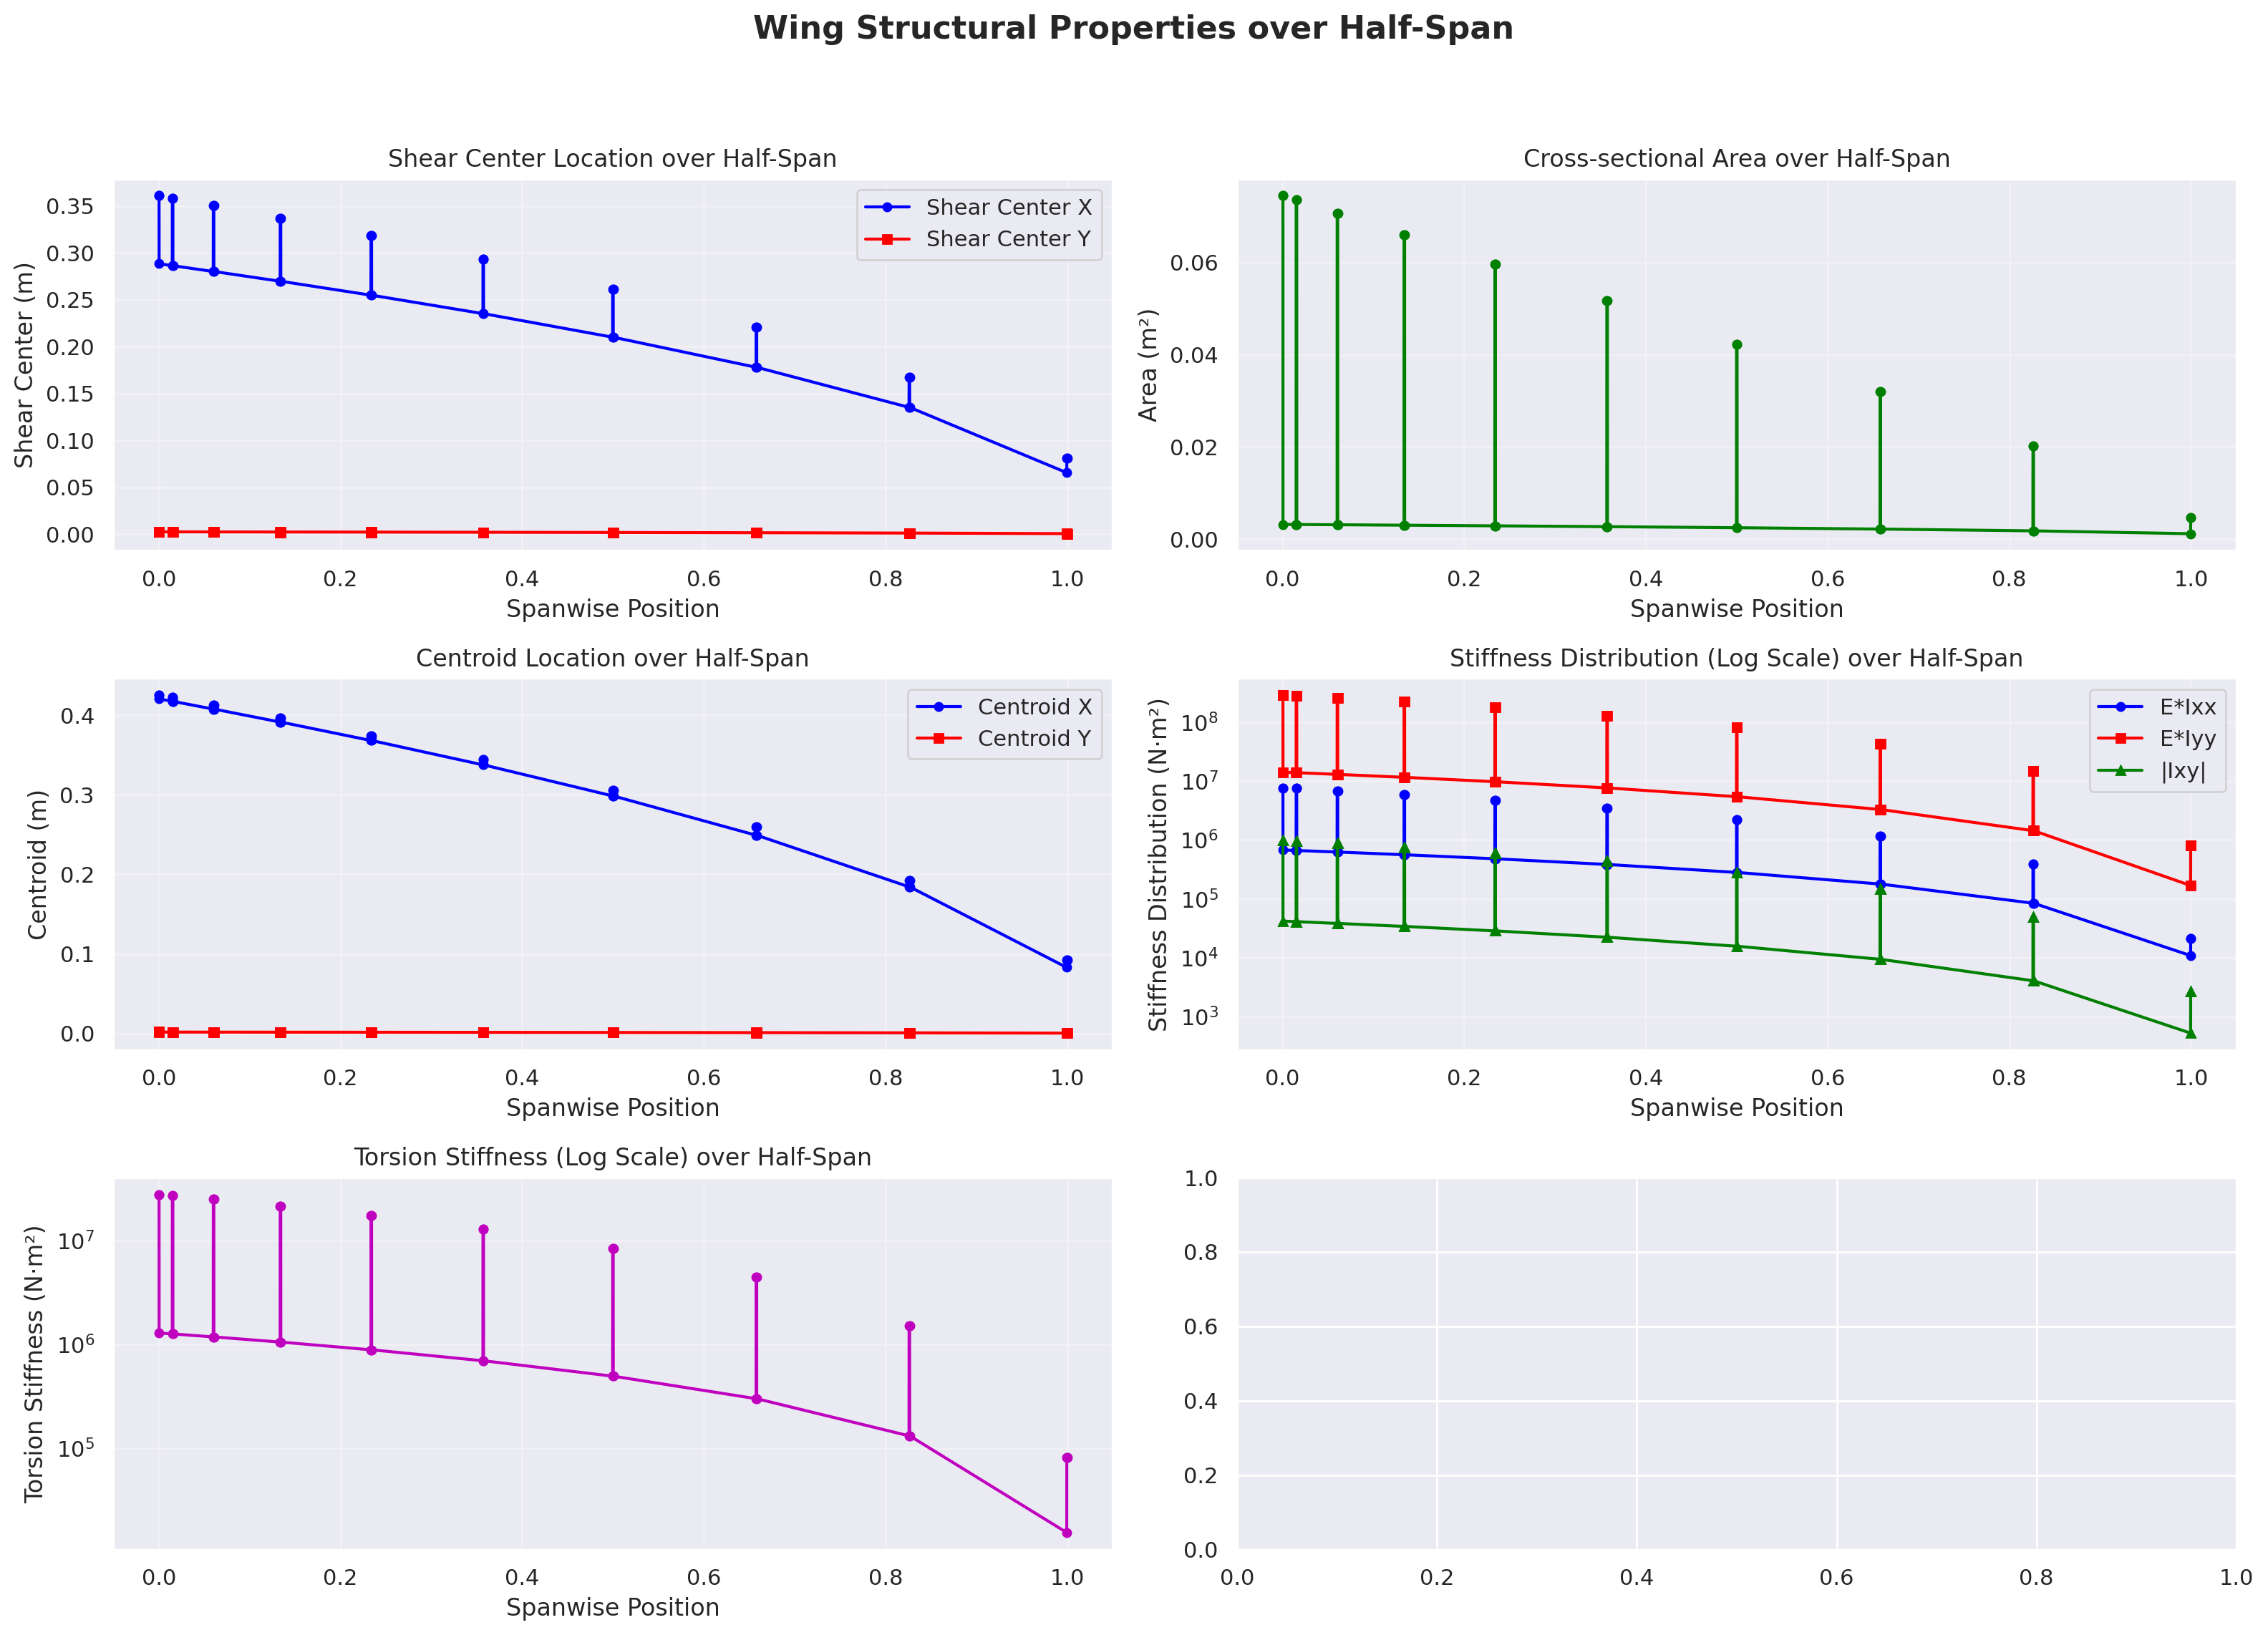

In [39]:

# Extract data for plotting
sc_x = [sc[0] if sc else None for sc in shear_centers]
sc_y = [sc[1] if sc else None for sc in shear_centers]

cent_x = [c[0] if c else None for c in centroids]
cent_y = [c[1] if c else None for c in centroids]

ixx = [sm[0] if sm else None for sm in second_moments_list]
iyy = [sm[1] if sm else None for sm in second_moments_list]
ixy = [sm[2] if sm else None for sm in second_moments_list]

# Create figure with subplots
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
fig.suptitle('Wing Structural Properties over Half-Span', fontsize=16, fontweight='bold')

# Plot 1: Shear Center
axes[0, 0].plot(y, sc_x, 'b-o', label='Shear Center X', markersize=4)
axes[0, 0].plot(y, sc_y, 'r-s', label='Shear Center Y', markersize=4)
axes[0, 0].set_xlabel('Spanwise Position')
axes[0, 0].set_ylabel('Shear Center (m)')
axes[0, 0].set_title('Shear Center Location over Half-Span')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Cross-sectional Area
axes[0, 1].plot(y, areas, 'g-o', markersize=4)
axes[0, 1].set_xlabel('Spanwise Position')
axes[0, 1].set_ylabel('Area (m²)')
axes[0, 1].set_title('Cross-sectional Area over Half-Span')
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Centroid
axes[1, 0].plot(y, cent_x, 'b-o', label='Centroid X', markersize=4)
axes[1, 0].plot(y, cent_y, 'r-s', label='Centroid Y', markersize=4)
axes[1, 0].set_xlabel('Spanwise Position')
axes[1, 0].set_ylabel('Centroid (m)')
axes[1, 0].set_title('Centroid Location over Half-Span')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Second Moments of Area
axes[1, 1].semilogy(y, ixx, 'b-o', label='E*Ixx', markersize=4)
axes[1, 1].semilogy(y, iyy, 'r-s', label='E*Iyy', markersize=4)
if any(i is not None for i in ixy):
    axes[1, 1].semilogy(y, [abs(i) if i else None for i in ixy], 'g-^', label='|Ixy|', markersize=4)
axes[1, 1].set_xlabel('Spanwise Position')
axes[1, 1].set_ylabel('Stiffness Distribution (N·m²)')
axes[1, 1].set_title('Stiffness Distribution (Log Scale) over Half-Span')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Plot 5: Torsion Constant GJ
axes[2, 0].semilogy(y, torsion_constants, 'm-o', markersize=4)
axes[2, 0].set_xlabel('Spanwise Position')
axes[2, 0].set_ylabel('Torsion Stiffness (N·m²)')
axes[2, 0].set_title('Torsion Stiffness (Log Scale) over Half-Span')
axes[2, 0].grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## 5) Scaling-Law Comparison
Compare directly computed properties with a root-scaled approximation along the half-span.

In [ ]:
# compute root values for beams not ribs
root_second_moments = second_moments_list[2]
root_gj = torsion_constants[2]
root_area = areas[2]
root_centroid = centroids[2]
root_shear_center = [sc_x[2], sc_y[2]]

root_rib_moments = second_moments_list[0]
root_rib_gj = torsion_constants[0]
root_rib_area = areas[0]
root_rib_centroid = [cent_x[0], cent_y[0]]
root_rib_shear_center = [sc_x[0], sc_y[0]]

# scale beam values
scaled_second_moments = [
    root_second_moments[0] * (chords**4),
    root_second_moments[1] * (chords**4),
    root_second_moments[2] * (chords**4),
]
scaled_gj = root_gj * (chords**4)
scaled_area = root_area * (chords**2)
scaled_centroid = [root_centroid[0] * (chords**1), root_centroid[1] * (chords**1)]
scaled_shear_center = [root_shear_center[0] * (chords**1), root_shear_center[1] * (chords**1)]

# scale rib values
scaled_rib_second_moments = [
    root_rib_moments[0] * (chords**4),
    root_rib_moments[1] * (chords**4),
    root_rib_moments[2] * (chords**4),
]
scaled_rib_gj = root_rib_gj * (chords**4)
scaled_rib_area = root_rib_area * (chords**2)
scaled_rib_centroid = [root_rib_centroid[0] * (chords**1), root_rib_centroid[1] * (chords**1)]
scaled_rib_shear_center = [root_rib_shear_center[0] * (chords**1), root_rib_shear_center[1] * (chords**1)]

y, scaled_shear_centers, scaled_areas, scaled_centroids, scaled_torsion_constants, scaled_second_moments_list = compose_scaled_properties(
    rib_positions,
    normalized_halfe_beam_thickness,
    (scaled_rib_shear_center, scaled_rib_area, scaled_rib_centroid, scaled_rib_gj, scaled_rib_second_moments),
    (scaled_shear_center, scaled_area, scaled_centroid, scaled_gj, scaled_second_moments),
)

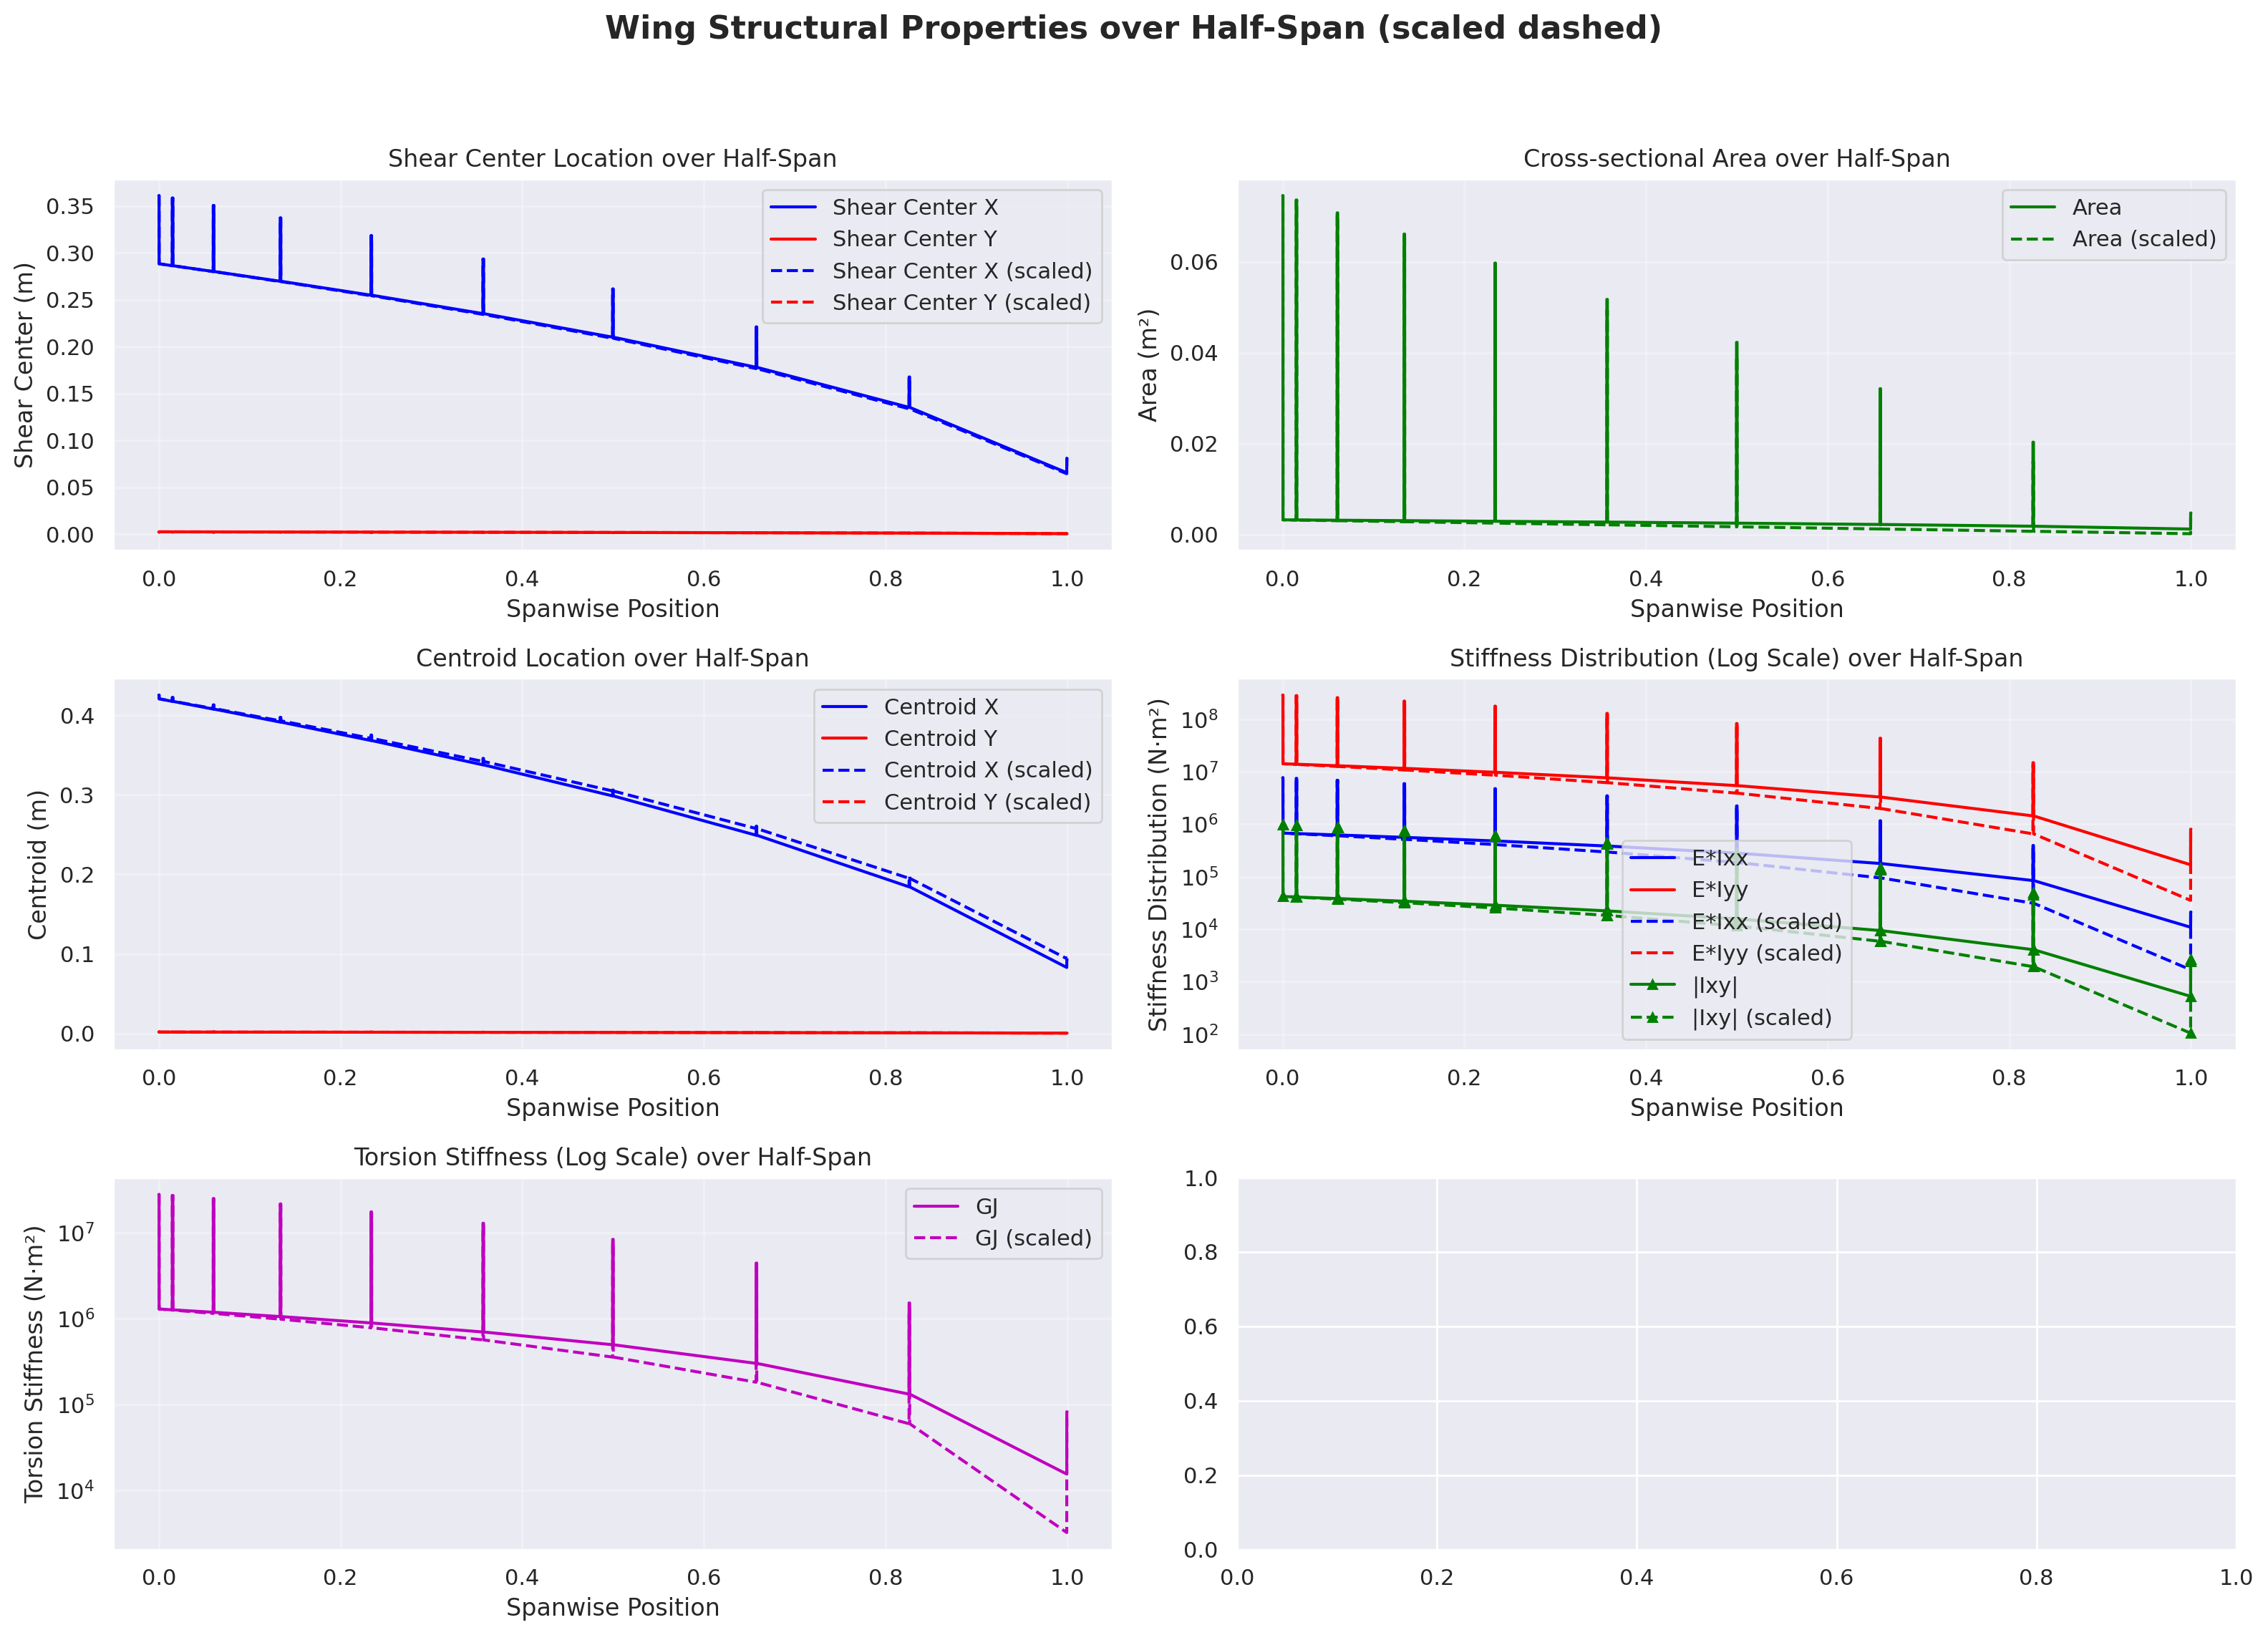

In [41]:

# Extract data for plotting
scaled_sc_x = [sc[0] if sc else None for sc in scaled_shear_centers]
scaled_sc_y = [sc[1] if sc else None for sc in scaled_shear_centers]

scaled_cent_x = [c[0] if c else None for c in scaled_centroids]
scaled_cent_y = [c[1] if c else None for c in scaled_centroids]

scaled_ixx = [sm[0] if sm else None for sm in scaled_second_moments_list]
scaled_iyy = [sm[1] if sm else None for sm in scaled_second_moments_list]
scaled_ixy = [sm[2] if sm and len(sm) > 2 else None for sm in scaled_second_moments_list]

# Create figure with subplots
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
fig.suptitle('Wing Structural Properties over Half-Span (scaled dashed)', fontsize=16, fontweight='bold')

# Plot 1: Shear Center
axes[0, 0].plot(y, sc_x, 'b-', label='Shear Center X', markersize=4)
axes[0, 0].plot(y, sc_y, 'r-', label='Shear Center Y', markersize=4)
axes[0, 0].plot(y, scaled_sc_x, 'b--', label='Shear Center X (scaled)', markersize=4)
axes[0, 0].plot(y, scaled_sc_y, 'r--', label='Shear Center Y (scaled)', markersize=4)
axes[0, 0].set_xlabel('Spanwise Position')
axes[0, 0].set_ylabel('Shear Center (m)')
axes[0, 0].set_title('Shear Center Location over Half-Span')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Cross-sectional Area
axes[0, 1].plot(y, areas, 'g-', label='Area', markersize=4)
axes[0, 1].plot(y, scaled_areas, 'g--', label='Area (scaled)', markersize=4)
axes[0, 1].set_xlabel('Spanwise Position')
axes[0, 1].set_ylabel('Area (m²)')
axes[0, 1].set_title('Cross-sectional Area over Half-Span')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Centroid
axes[1, 0].plot(y, cent_x, 'b-', label='Centroid X', markersize=4)
axes[1, 0].plot(y, cent_y, 'r-', label='Centroid Y', markersize=4)
axes[1, 0].plot(y, scaled_cent_x, 'b--', label='Centroid X (scaled)', markersize=4)
axes[1, 0].plot(y, scaled_cent_y, 'r--', label='Centroid Y (scaled)', markersize=4)
axes[1, 0].set_xlabel('Spanwise Position')
axes[1, 0].set_ylabel('Centroid (m)')
axes[1, 0].set_title('Centroid Location over Half-Span')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Second Moments of Area
axes[1, 1].semilogy(y, ixx, 'b-', label='E*Ixx', markersize=4)
axes[1, 1].semilogy(y, iyy, 'r-', label='E*Iyy', markersize=4)
axes[1, 1].semilogy(y, scaled_ixx, 'b--', label='E*Ixx (scaled)', markersize=4)
axes[1, 1].semilogy(y, scaled_iyy, 'r--', label='E*Iyy (scaled)', markersize=4)
if any(i is not None for i in ixy):
    axes[1, 1].semilogy(y, [abs(i) if i else None for i in ixy], 'g-^', label='|Ixy|', markersize=4)
    axes[1, 1].semilogy(y, [abs(i) if i else None for i in scaled_ixy], 'g--^', label='|Ixy| (scaled)', markersize=4)
axes[1, 1].set_xlabel('Spanwise Position')
axes[1, 1].set_ylabel('Stiffness Distribution (N·m²)')
axes[1, 1].set_title('Stiffness Distribution (Log Scale) over Half-Span')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

# Plot 5: Torsion Constant GJ
axes[2, 0].semilogy(y, torsion_constants, 'm-', label='GJ', markersize=4)
axes[2, 0].semilogy(y, scaled_torsion_constants, 'm--', label='GJ (scaled)', markersize=4)
axes[2, 0].set_xlabel('Spanwise Position')
axes[2, 0].set_ylabel('Torsion Stiffness (N·m²)')
axes[2, 0].set_title('Torsion Stiffness (Log Scale) over Half-Span')
axes[2, 0].legend()
axes[2, 0].grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## 6) Area-Preserving Smoothing and Interpolation
Smooth piecewise spanwise properties using boxcar averaging at rib locations and interpolate to solver stations.

approximated integral of last bin: 42381.94200093051
last value of smoothed Iyy: 488135.75322652824


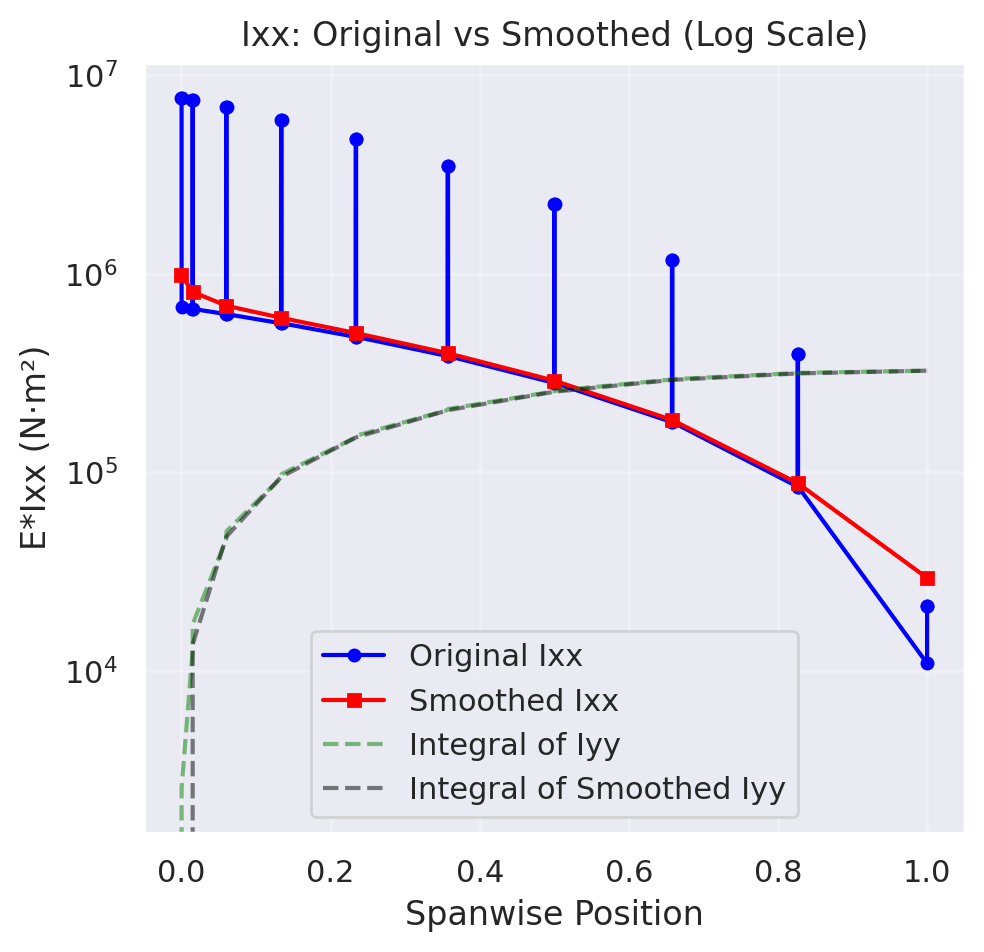

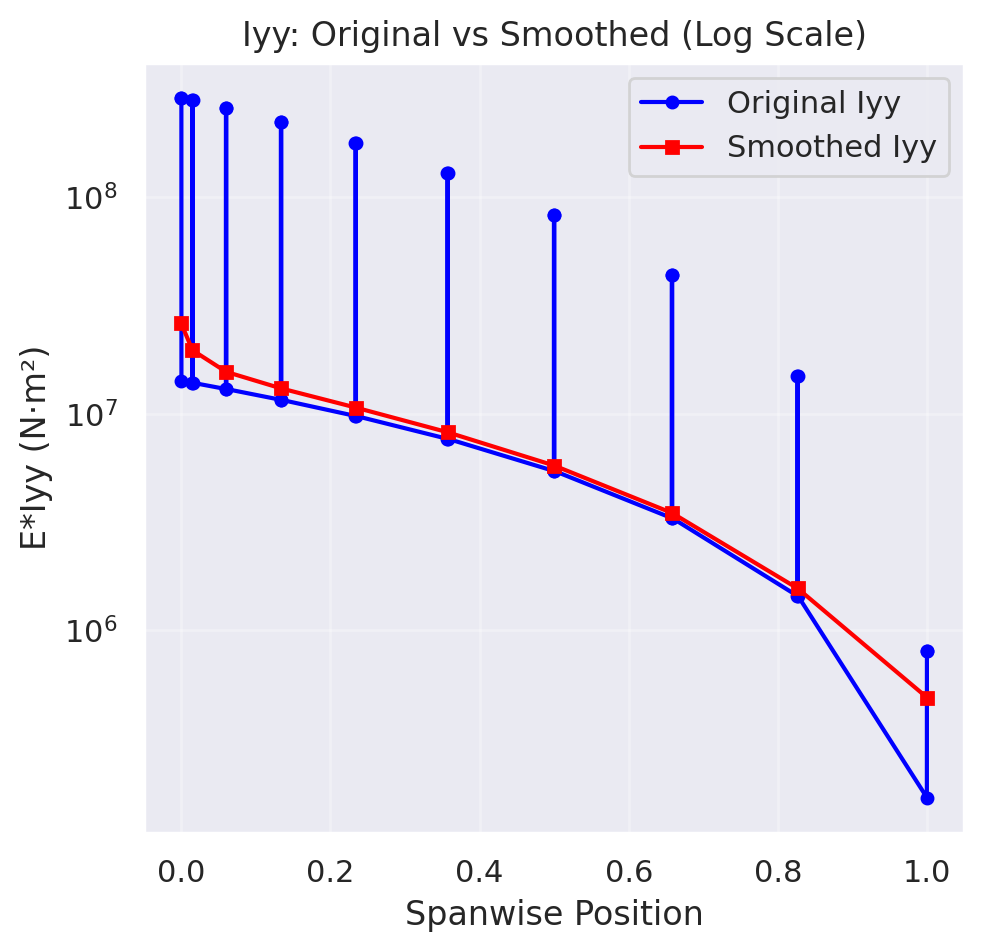

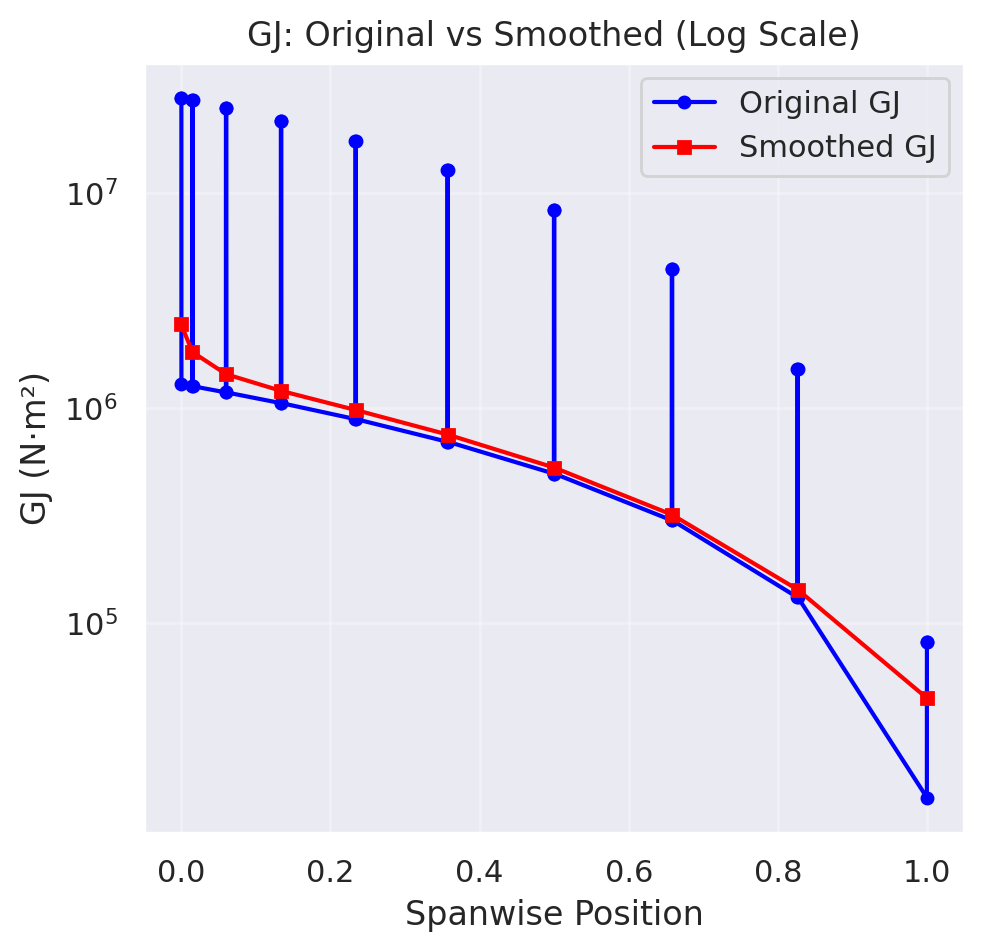

In [ ]:
ixx_func = [y, ixx]
iyy_func = [y, iyy]
j_func = [y, torsion_constants]

# apply smoothing
out_y = rib_positions
Ixx_smooth_func = area_preserving_boxcar(ixx_func, out_y)
Iyy_smooth_func = area_preserving_boxcar(iyy_func, out_y)
J_smooth_func = area_preserving_boxcar(j_func, out_y)

print(f"approximated integral of last bin: {Iyy_smooth_func[1][-1] * (Iyy_smooth_func[0][-1] - ((Iyy_smooth_func[0][-1] + Iyy_smooth_func[0][-2]) / 2))}")
print(f"last value of smoothed Iyy: {Iyy_smooth_func[1][-1]}")

ys = np.asarray(Ixx_smooth_func[0], dtype=float)
fs = np.asarray(Ixx_smooth_func[1], dtype=float)
integ_areas = 0.5 * (fs[1:] + fs[:-1]) * np.diff(ys)
F_ixx = np.r_[0.0, np.cumsum(integ_areas)]

# cumulative of ORIGINAL curve (piecewise-linear through original samples)
y_arr = np.asarray(ixx_func[0], dtype=float)
f_arr = np.asarray(ixx_func[1], dtype=float)
integ_areas = 0.5 * (f_arr[1:] + f_arr[:-1]) * np.diff(y_arr)
F_ixx_orig = np.r_[0.0, np.cumsum(integ_areas)]

#Plot comparison of smoothed vs original
plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 1)
plt.semilogy(ixx_func[0], ixx_func[1], 'b-o', label='Original Ixx', markersize=4)
plt.semilogy(Ixx_smooth_func[0], Ixx_smooth_func[1], 'r-s', label='Smoothed Ixx', markersize=4)
plt.semilogy(iyy_func[0], F_ixx_orig, 'g--', label='Integral of Iyy', markersize=4, alpha=0.5)
plt.semilogy(Iyy_smooth_func[0], F_ixx, 'k--', label='Integral of Smoothed Iyy', markersize=4, alpha=0.5)
plt.xlabel('Spanwise Position')
plt.ylabel('E*Ixx (N·m²)')
plt.title('Ixx: Original vs Smoothed (Log Scale)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 2)
# debugging last values with lines in linear scale
#plt.plot(iyy_func[0][-8:], iyy_func[1][-8:], 'b-o', label='Original Iyy', markersize=4)
#plt.plot(Iyy_smooth_func[0][-3:], Iyy_smooth_func[1][-3:], 'r-s', label='Smoothed Iyy', markersize=4)
#plt.axvline(x=0.5*(Iyy_smooth_func[0][-1]+Iyy_smooth_func[0][-2]), color='gray', linestyle='--', label='last section')
#plt.plot(iyy_func[0][-6:], np.ones_like(iyy_func[0][-6:])*Iyy_smooth_func[1][-1], 'b--', label='Original Iyy', markersize=4, alpha=0.2)
plt.xlabel('Spanwise Position')
plt.semilogy(iyy_func[0], iyy_func[1], 'b-o', label='Original Iyy', markersize=4)
plt.semilogy(Iyy_smooth_func[0], Iyy_smooth_func[1], 'r-s', label='Smoothed Iyy', markersize=4)
plt.xlabel('Spanwise Position')
plt.ylabel('E*Iyy (N·m²)')
plt.title('Iyy: Original vs Smoothed (Log Scale)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 3)
plt.semilogy(y, torsion_constants, 'b-o', label='Original GJ', markersize=4)
plt.semilogy(J_smooth_func[0], J_smooth_func[1], 'r-s', label='Smoothed GJ', markersize=4)
plt.xlabel('Spanwise Position')
plt.ylabel('GJ (N·m²)')
plt.title('GJ: Original vs Smoothed (Log Scale)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [ ]:
Ixx_final = interpolate_smoothed(Ixx_smooth_func, ys_over_half_span)
Iyy_final = interpolate_smoothed(Iyy_smooth_func, ys_over_half_span)
J_final = interpolate_smoothed(J_smooth_func, ys_over_half_span)

print("Final interpolated properties at specified spanwise locations:")
print(Ixx_final)
print(Iyy_final)
print(J_final)

Final interpolated properties at specified spanwise locations:
[982083.37142314 377993.83875578 155430.75421128  55082.39520294
  29317.30020638]
[26152338.70055084  7771428.91025499  2919388.81392004   958112.63787247
   488135.75322653]
[2450304.22880777  713838.9345431   268246.06147177   88027.20905299
   44764.33871661]


## 7) Scaled vs Computed (Smoothed)
Final comparison of smoothed direct-computation properties versus smoothed scaling-law estimates.

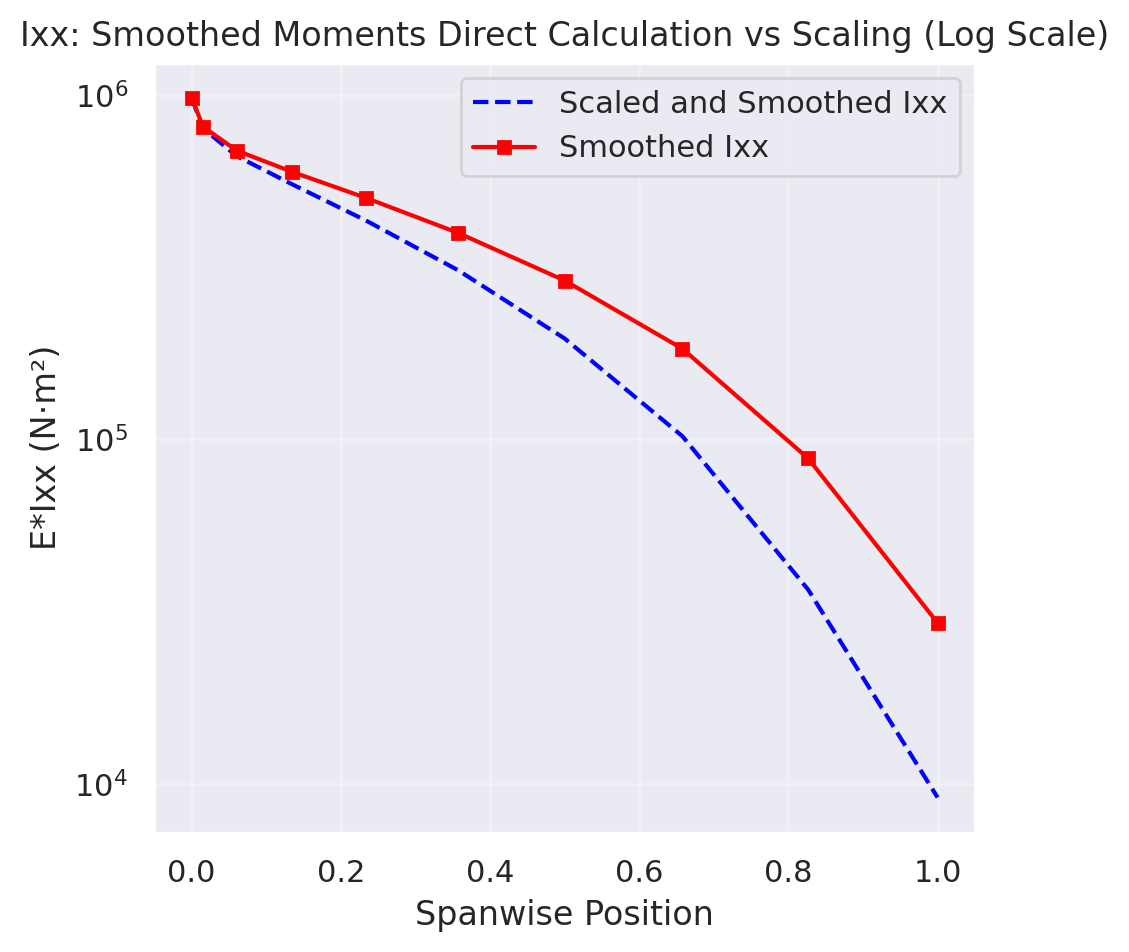

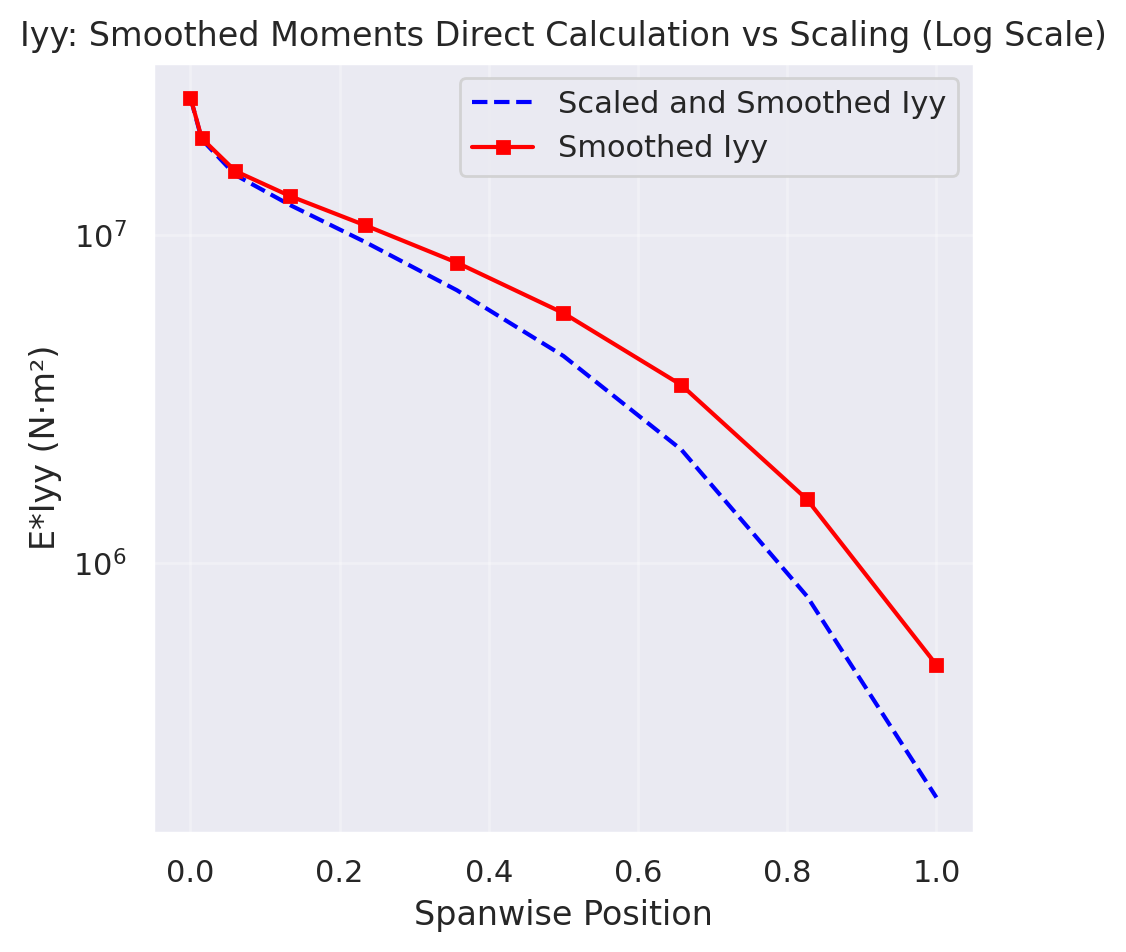

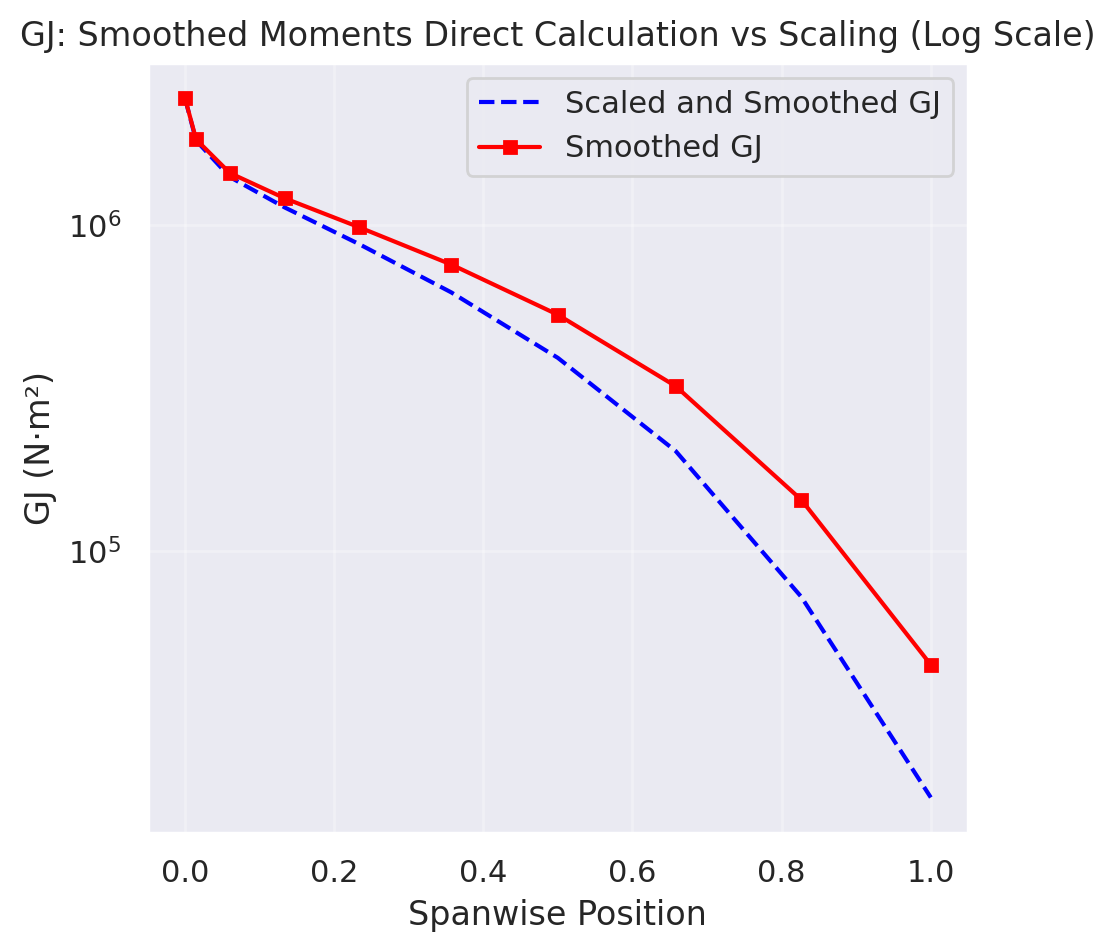

In [45]:
# comparison of scaled vs computed values smoothed
scaled_ixx_func = [y, scaled_ixx]
scaled_iyy_func = [y, scaled_iyy]
scaled_j_func = [y, scaled_torsion_constants]

# apply smoothing
out_y = rib_positions
scaled_Ixx_smooth_func = area_preserving_boxcar(scaled_ixx_func, out_y)
scaled_Iyy_smooth_func = area_preserving_boxcar(scaled_iyy_func, out_y)
scaled_J_smooth_func = area_preserving_boxcar(scaled_j_func, out_y)

yss = np.asarray(scaled_Iyy_smooth_func[0], dtype=float)    # x
fss = np.asarray(scaled_Iyy_smooth_func[1], dtype=float)    # f(x)
integ_areas = 0.5 * (fss[1:] + fss[:-1]) * np.diff(yss)
F_scaled_iyy = np.r_[0.0, np.cumsum(integ_areas)]

#Plot comparison of smoothed vs original
plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 1)
plt.semilogy(scaled_Ixx_smooth_func[0], scaled_Ixx_smooth_func[1], 'b--', label='Scaled and Smoothed Ixx', markersize=4)
plt.semilogy(Ixx_smooth_func[0], Ixx_smooth_func[1], 'r-s', label='Smoothed Ixx', markersize=4)
plt.xlabel('Spanwise Position')
plt.ylabel('E*Ixx (N·m²)')
plt.title('Ixx: Smoothed Moments Direct Calculation vs Scaling (Log Scale)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 2)
plt.xlabel('Spanwise Position')
plt.semilogy(scaled_Iyy_smooth_func[0], scaled_Iyy_smooth_func[1], 'b--', label='Scaled and Smoothed Iyy', markersize=4)
plt.semilogy(Iyy_smooth_func[0], Iyy_smooth_func[1], 'r-s', label='Smoothed Iyy', markersize=4)
plt.xlabel('Spanwise Position')
plt.ylabel('E*Iyy (N·m²)')
plt.title('Iyy: Smoothed Moments Direct Calculation vs Scaling (Log Scale)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plt.figure(figsize=(18, 5))
plt.subplot(1, 3, 3)
plt.semilogy(scaled_J_smooth_func[0], scaled_J_smooth_func[1], 'b--', label='Scaled and Smoothed GJ', markersize=4)
plt.semilogy(J_smooth_func[0], J_smooth_func[1], 'r-s', label='Smoothed GJ', markersize=4)
plt.xlabel('Spanwise Position')
plt.ylabel('GJ (N·m²)')
plt.title('GJ: Smoothed Moments Direct Calculation vs Scaling (Log Scale)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()